In [1]:
import pandas as pd

df = pd.read_csv("tokopedia_product_reviews_2025.csv")  # ganti dengan nama file-mu

print(df.shape)
print(df.columns.tolist())  # lihat semua nama kolom
print(df.head())
print(df.isnull().sum())

(65543, 13)
['review_text', 'review_date', 'review_id', 'product_name', 'product_category', 'product_variant', 'product_price', 'product_url', 'product_id', 'rating', 'sold_count', 'shop_id', 'sentiment_label']
                                         review_text review_date   review_id  \
0  baru sekali ini terima brg dr belanja online d...  2024-12-22  1134256160   
1  cocok bgt aku sama telur nya. nga Amis menurut...  2025-02-25  1242584634   
2  Telornya sudah sampai di rumah dengan kemasan ...  2025-07-15  1573444677   
3  Telor sudah diterima dengan baik dan tidak ada...  2025-07-20  1581728541   
4  Alhamdulillah penjual amanah,Telor nya terbaik...  2023-04-24   881041355   

                                        product_name   product_category  \
0  Telur Ayam Kampung Asli - Telur Mengandung Ome...  Makanan & Minuman   
1  Telur Ayam Kampung Asli - Telur Mengandung Ome...  Makanan & Minuman   
2  Telur Ayam Kampung Asli - Telur Mengandung Ome...  Makanan & Minuman   
3  Telur

In [2]:
print(df["sentiment_label"].value_counts())

sentiment_label
positive    63943
neutral       802
negative      798
Name: count, dtype: int64


In [3]:
# 1. Distribusi label
print(df["sentiment_label"].value_counts())
print(df["sentiment_label"].value_counts(normalize=True).round(3))

# 2. Hubungan label dengan rating
print(pd.crosstab(df["rating"], df["sentiment_label"]))

# 3. Duplikat
print("Review duplikat:", df["review_text"].duplicated().sum())

# 4. Panjang teks (jumlah kata)
df["n_words"] = df["review_text"].str.split().str.len()
print(df["n_words"].describe())

sentiment_label
positive    63943
neutral       802
negative      798
Name: count, dtype: int64
sentiment_label
positive    0.976
neutral     0.012
negative    0.012
Name: proportion, dtype: float64
sentiment_label  negative  neutral  positive
rating                                      
1                     547        0         0
2                     251        0         0
3                       0      802         0
4                       0        0      2418
5                       0        0     61525
Review duplikat: 7475
count    65543.000000
mean        11.905833
std         34.726936
min          1.000000
25%          5.000000
50%          9.000000
75%         14.000000
max       7932.000000
Name: n_words, dtype: float64


In [4]:
for label in df["sentiment_label"].unique():
    print(f"\n=== {label} ===")
    for text in df[df["sentiment_label"] == label]["review_text"].sample(3, random_state=42):
        print("-", text[:200])


=== positive ===
- Seller garcep &amp; amanah, manteb pokoknya👍👍
- TERIMA KASIH, PAKET SDH SAMPAI. *PENGIRIMAN : Sangat CPT *KWALITAS BRG: MEMUASKAN sesuai diskripsi. *PENGEMASAN : AMAN n RAPI **REKOMENDED &amp; SUKSES SELALU 🙏
- bagus semoga awet

=== negative ===
- Tolong jangan di beli di tokoh ini lagi pesanan tidak sesuai
- Barang bagus, tapi size kekecilan, dan tidak bisa di tukar.
- layanan toko sacks, minta pengiriman instant tp ga instant, ORANG BELI PRODUK INI TUH KARENA MAU CEPAT, MAU LEBIH EFISIEN TAPI KECEWA BGT KARENA KENYATAANNYA PELAYANAN SUPER LEMOT

=== neutral ===
- Awal minum wangi banget tapi kok lama lama enek ya 😅😅
- dari semua varian, varian ini wangginya yang paling enak, perbaiki dong berat produk agar sesuai dengan berat dan volume metrik aktual agar pembeli tidak membayar ongkir lebih, 5 pcs masa beratnya 1.5
- Kuahnya basi


In [5]:
# 1. Teks yang sama tapi label berbeda
conflict = df.groupby("review_text")["sentiment_label"].nunique()
print("Teks dengan label bertentangan:", (conflict > 1).sum())

# 2. Teks yang paling sering berulang
print(df["review_text"].value_counts().head(10))

# 3. Duplikat ini berasal dari label mana?
dup = df[df["review_text"].duplicated(keep="first")]
print(dup["sentiment_label"].value_counts())

Teks dengan label bertentangan: 15
review_text
Bagus               323
mantap              288
bagus               226
Mantap              193
Good                127
good                 92
sesuai pesanan       77
sesuai               61
mantab               50
sesuai deskripsi     48
Name: count, dtype: int64
sentiment_label
positive    7443
neutral       20
negative      12
Name: count, dtype: int64


In [9]:
import re, html

slang = {
    "brg": "barang", "bgt": "banget", "sdh": "sudah", "udh": "sudah",
    "dr": "dari", "yg": "yang", "tp": "tapi", "gk": "tidak", "ga": "tidak",
    "nga": "tidak", "gak": "tidak", "tdk": "tidak", "krn": "karena",
    "jg": "juga", "dgn": "dengan", "cpt": "cepat", "kwalitas": "kualitas",
    "sy": "saya", "blm": "belum", "garcep": "gerak cepat",
}

def clean_text(t):
    t = html.unescape(t).lower()          # &amp; -> &, lalu huruf kecil
    t = re.sub(r"http\S+", " ", t)        # hapus URL
    t = re.sub(r"[^a-z\s]", " ", t)       # hapus emoji, angka, tanda baca
    t = re.sub(r"(.)\1{2,}", r"\1", t)    # bagusss -> bagus
    words = [slang.get(w, w) for w in t.split()]
    return " ".join(words[:200])          # batasi 200 kata untuk outlier

df["clean_text"] = df["review_text"].apply(clean_text)

# Buang teks kosong setelah dibersihkan (misal review isinya emoji saja)
df = df[df["clean_text"].str.len() > 0]

In [10]:
conflict = df.groupby("clean_text")["sentiment_label"].nunique()
conflict_texts = conflict[conflict > 1].index
print("Teks dengan label bertentangan:", len(conflict_texts))

# Buang semua teks yang bertentangan (labelnya tidak bisa dipercaya)
df = df[~df["clean_text"].isin(conflict_texts)]

# Buang duplikat
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)

print(df.shape)
print(df["sentiment_label"].value_counts())

Teks dengan label bertentangan: 0
(55501, 15)
sentiment_label
positive    53959
negative      779
neutral       763
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["sentiment_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(y_train.value_counts())
print(y_test.value_counts())

sentiment_label
positive    43167
negative      623
neutral       610
Name: count, dtype: int64
sentiment_label
positive    10792
negative      156
neutral       153
Name: count, dtype: int64


In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(classification_report(y_test, dummy.predict(X_test), zero_division=0))

              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       156
     neutral       0.00      0.00      0.00       153
    positive       0.97      1.00      0.99     10792

    accuracy                           0.97     11101
   macro avg       0.32      0.33      0.33     11101
weighted avg       0.95      0.97      0.96     11101



In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3,
                              max_features=50000, sublinear_tf=True)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

model.fit(X_train, y_train)
pred = model.predict(X_test)
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

    negative       0.34      0.58      0.43       156
     neutral       0.17      0.44      0.25       153
    positive       0.99      0.96      0.98     10792

    accuracy                           0.95     11101
   macro avg       0.50      0.66      0.55     11101
weighted avg       0.97      0.95      0.96     11101



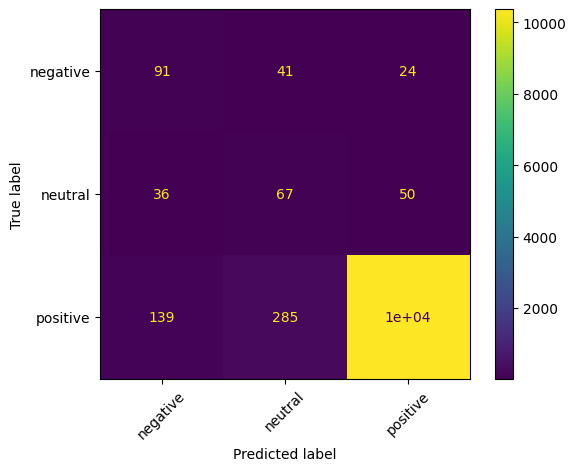

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45)

In [16]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    model,
    param_grid={"clf__C": [0.3, 1, 3, 10]},
    scoring="f1_macro",   # kelas kecil dihitung sama penting
    cv=3,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("C terbaik:", grid.best_params_)
print("Macro F1 (CV):", round(grid.best_score_, 3))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
C terbaik: {'clf__C': 10}
Macro F1 (CV): 0.56


In [17]:
best = grid.best_estimator_
pred_best = best.predict(X_test)
print(classification_report(y_test, pred_best))

              precision    recall  f1-score   support

    negative       0.43      0.48      0.46       156
     neutral       0.20      0.29      0.24       153
    positive       0.99      0.98      0.98     10792

    accuracy                           0.96     11101
   macro avg       0.54      0.58      0.56     11101
weighted avg       0.97      0.96      0.97     11101



In [18]:
import joblib
joblib.dump(best, "sentiment_model.joblib")
print("Tersimpan")

Tersimpan


In [19]:
import sklearn
print(sklearn.__version__)

1.6.1
